# Layer fidelity: how good is a whole line of qubits?

## The problem

The randomized benchmarking notebook measured the error of the gates on one qubit. A real circuit does more. It uses many qubits, it runs gates on several of them at once, and its two-qubit gates have a larger error than its one-qubit gates: typically about 1% per two-qubit gate against about 0.1% per one-qubit gate. A device with excellent one-qubit gates can still be a poor machine for circuits that entangle qubits.

We want one number that says how well a chain of $N$ qubits works when it is used this way. The number is the **layer fidelity**: a score between 0 and 1 for a whole chain, where 1 means every gate on the chain does exactly what it should. The idea is the one from randomized benchmarking applied to every link of the chain.

A **link** is a pair of neighboring qubits that a two-qubit gate can act on. A chain of $N$ qubits has $N-1$ links. Qubits are numbered from 0, and "link 0-1" is the link between qubits 0 and 1.

The method has four parts, (a) to (d):

- (a) **Split the links into layers.** A layer is a set of two-qubit gates that run at the same time. A qubit takes part in one gate at a time, so two links that share a qubit cannot be in the same layer. A chain needs two layers: the even links (0-1, 2-3, ...) and the odd links (1-2, 3-4, ...).
- (b) **Run randomized benchmarking on every link of a layer simultaneously**, each with its own random two-qubit gates. Running them together includes the **crosstalk** between neighbors (a gate disturbing the qubits next to it), which a test of one link alone leaves out.
- (c) **Fit the decay of each link** and convert its decay rate to a **process fidelity**, a score for one link that is defined below in Step 1.
- (d) **Multiply the $N-1$ process fidelities.** The product is the layer fidelity.

A single number for a chain would hide a weak link, so the notebook also shows the fidelity of each link.

## The workflow

| Step | What it does | Code |
|---|---|---|
| 1. Operator | The layers, the decay model of a pair, and the layer fidelity | `ops.py` |
| 2. Encoding | Put one random sequence for each link of a layer into one circuit | `encoding.py` |
| 3. Execution | Run every layer, length, and random draw as one job | `execution.py` |
| 4. Analysis | Fit each link, multiply the fidelities, plot | `analysis.py` |

The same steps run from the command line with `python layer_fidelity/main.py`, started in `../scripts/`.

## Setup

By default this notebook runs on the **Aer simulator**, a program on your computer that applies the gates and the noise to the state by calculation, so no quantum hardware is needed. The chain has 4 qubits (3 links). Each CX gate has a **depolarizing error**: with some probability the state of the two qubits is replaced by a random state, and otherwise the gate works. The probability depends on the link: 1.0% on link 0-1, 2.5% on link 1-2, and 1.5% on link 2-3. Read-out also has an error: a qubit in state 0 is read as 1 with probability 2%, and a qubit in state 1 is read as 0 with probability 4%. Because we know the noise we put in, we can check the answer. To measure a real chain, set `backend_name = "ibm_rensselaer"` and give `chain`, the physical qubits in order (the numbers the device gives its qubits, as opposed to the numbers 0, 1, 2, ... that the circuit uses). Each consecutive pair must be connected on the device.

The code lives in four helper modules in `scripts/layer_fidelity/`. `ops.py` has the layers, the decay model, and the fidelity formulas. `encoding.py` builds and compiles the circuits. `execution.py` runs them, and `analysis.py` fits and plots. You do not need to read them; the notebook calls them and explains what they return.

- `n_qubits`: chain length on the simulator. On hardware it is the length of `chain`.
- `lengths`: numbers $m$ of two-qubit Cliffords per sequence. A **sequence** is $m$ random Cliffords followed by the one Clifford that undoes them all. The longest should let the survival fall most of the way to its floor of 0.25 (Step 1 explains the floor). The code cell prints the 9 values.
- `sequences`: random sequences per length and link.
- `shots`: repetitions of each circuit.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from qiskit.quantum_info import Operator

# The layer fidelity code lives in ../scripts/layer_fidelity.
# Run this notebook from its own folder (the Jupyter default).
sys.path.insert(0, str(Path("../scripts/layer_fidelity").resolve()))

import analysis
import encoding as enc
import execution
import ops

%matplotlib inline

backend_name = None  # None = Aer simulator, or e.g. "ibm_rensselaer"
chain = None  # physical qubits in order on hardware, e.g. [0, 1, 2, 3]
n_qubits = 4 if chain is None else len(chain)
lengths = ops.LENGTHS
print("lengths:", lengths)
sequences = 20
shots = 500
seed = 1

lengths: (1, 2, 4, 8, 16, 24, 32, 48, 64)


## Step 1: The operator (layers and fidelities)

### The layers

`link_layers` splits the links of a chain into the two layers. Each link is printed as a pair such as `(0, 1)`, meaning qubits 0 and 1. For 4 qubits the even layer runs links 0-1 and 2-3 together, and the odd layer runs link 1-2 alone. For 6 qubits the odd layer has two links. Two layers are enough because each qubit in a chain has at most two neighbors: the links alternate, so no two links of one layer share a qubit.

In [2]:
for n in (4, 6):
    print(f"{n} qubits:", ops.link_layers(n))

4 qubits: [[(0, 1), (2, 3)], [(1, 2)]]
6 qubits: [[(0, 1), (2, 3), (4, 5)], [(1, 2), (3, 4)]]


### Randomized benchmarking of a pair

Recall the single-qubit method. We apply $m$ random Cliffords followed by the Clifford that undoes them all. Without noise the qubit returns to its start, so we can read the **survival probability**: the fraction of shots that return the start state. It decays as $A\,p^m + B$, where $p$ is the decay rate per Clifford. We write the survival probability as $F(m)$, as in that notebook.

For a pair of qubits we start in 00 and define the survival probability $F(m)$ as the fraction of shots in which both qubits read 0. A pair has $d = 4$ outcomes (00, 01, 10, 11). A completely scrambled pair gives each outcome equally often, so a random guess hits 00 one time in four. The floor is therefore $B = 1/d = \tfrac14$. (For one qubit, $d=2$ and $B=\tfrac12$.) We fit

$$F(m) = A\,p^m + B, \qquad B \approx \tfrac14 \text{ in the ideal case.}$$

The two-qubit Cliffords form a set of 11,520 different gates (the size of the set; we never list them). Qiskit draws one at random with `random_clifford(2)` and writes it as a circuit of CX and one-qubit gates. As for one qubit, a product of Cliffords is again a Clifford, so the last gate, the inverse of all the others, is in the same set. This closure is why a single gate can undo the whole sequence.

### From the decay rate to the error of a link

As before, we model each Clifford as keeping the state with probability $p$ and replacing it with a random state with probability $1-p$. A gate can then be scored in two ways.

1. **Average error** $r$. This is the chance that the gate gives the wrong answer for a typical input state. For a scrambled output the answer is wrong with probability $(d-1)/d$ (3 out of 4 outcomes for a pair), so
$$r = (1-p)\,\frac{d-1}{d}.$$
For one qubit, $d=2$ gives $r=(1-p)/2$, the formula from the previous notebook.
2. **Process fidelity** PF. This is a stricter score. It compares the whole input-to-output map of the gate, not the result for one input state. A pair has $d^2 = 16$ input/output combinations, and a random map matches the ideal one in one of them. With probability $p$ the gate is perfect, and with probability $1-p$ it is a random map, so
$$\mathrm{PF} = p + \frac{1-p}{d^2}.$$
PF is the standard definition used for layer fidelity.

The two scores are linked. The process error is

$$1 - \mathrm{PF} = (1-p) - \frac{1-p}{d^2} = (1-p)\,\frac{d^2-1}{d^2}.$$

Since $d^2 - 1 = (d-1)(d+1)$, multiplying by $d/(d+1)$ gives

$$\frac{d}{d+1}\,(1 - \mathrm{PF}) = (1-p)\,\frac{(d-1)(d+1)}{d^2}\cdot\frac{d}{d+1} = (1-p)\,\frac{d-1}{d} = r.$$

So the factor $d/(d+1)$ converts the process error into the average error. For a pair, $d/(d+1) = 4/5$.

**Worked check.** One link has $p = 0.98$. Then $\mathrm{PF} = 0.98 + 0.02/16 = 0.98125$, and $\tfrac45(1 - 0.98125) = 0.015$. The direct formula gives $r = (1-0.98)\cdot\tfrac34 = 0.015$. The two agree.

### The layer fidelity

The **layer fidelity** is the product of the process fidelities of all the links,

$$\mathrm{LF} = \mathrm{PF}_1\,\mathrm{PF}_2\cdots\mathrm{PF}_{N-1}.$$

It falls as the chain gets longer, which makes chains of different lengths hard to compare. The **error per layered gate** (EPLG) divides that out:

$$\mathrm{EPLG} = \tfrac45\left(1 - \mathrm{LF}^{1/(N-1)}\right).$$

$\mathrm{LF}^{1/(N-1)}$ is the **geometric mean** of the link fidelities (the $(N-1)$th root of their product). It is the process fidelity of a typical link. One minus it is the process error of a typical link, and the factor $4/5$ turns that into the average error $r$. So EPLG is the average error of a typical link.

**Worked example.** Three links have process fidelities 0.99, 0.97, and 0.98.

1. Multiply: $\mathrm{LF} = 0.99 \times 0.97 \times 0.98 = 0.9411$.
2. Take the geometric mean: $0.9411^{1/3} = 0.9800$.
3. Convert: $\mathrm{EPLG} = \tfrac45(1 - 0.9800) = 0.0160$.

**Check.** The process errors of the three links are 0.01, 0.03, and 0.02. Their mean is 0.02, and $\tfrac45 \times 0.02 = 0.0160$. This matches step 3, as it should: for small errors $e_i$, the product $(1-e_1)(1-e_2)(1-e_3)$ is close to $1 - (e_1+e_2+e_3)$, because products of two small errors are negligible, so $1-\mathrm{LF}^{1/3}$ is close to the mean error.

In [3]:
pf = [0.99, 0.97, 0.98]
lf = ops.layer_fidelity(pf)
print(f"LF = {lf:.4f}")
print(f"geometric mean = {lf ** (1 / 3):.4f}")
print(f"EPLG = {ops.eplg(lf, 3):.4f}")
print(f"4/5 x mean process error = {0.8 * np.mean(1 - np.array(pf)):.4f}")

LF = 0.9411
geometric mean = 0.9800
EPLG = 0.0160
4/5 x mean process error = 0.0160


**Stop and think.**

1. **Question.** One link at 0.90 and two at 0.99 give $\mathrm{LF} = 0.882$. Three links at 0.959 give the same LF. Which chain is better for a circuit that uses only the two good links of the first chain, and what does the layer fidelity not tell you? **Answer.** The first chain: its two good links give $0.99^2 = 0.980$, against $0.959^2 = 0.920$ for the second. The layer fidelity is one number for the whole chain, so it cannot tell you which links are weak. That is why the per-link fidelities are reported too.
2. **Question.** Why does a chain need only two layers, and would a grid of qubits? **Answer.** Each qubit in a chain has at most two neighbors, so alternate links never share a qubit. A qubit in a grid can have four neighbors, so a grid needs more layers.
3. **Question.** Would this simulator give different results if the links of a layer ran alone instead of together? **Answer.** No. The noise on each link is independent of the others, so there is no crosstalk to see. On hardware, neighboring gates do disturb each other, and running the layer together is built to include that.

## Step 2: Encoding (one layer circuit)

For every link in the layer we draw a random sequence of $m$ two-qubit Cliffords plus the inverse, and place them on the qubits of the link. All the links of the layer share one circuit, so they run at the same time. A barrier after each Clifford keeps the compiler from merging neighbors. A qubit that is in no link of the layer does nothing.

`build_layer_circuit(layer, n_qubits, m, rng)` takes the `layer` (a list of links such as `(0, 1)`), the number of qubits `n_qubits` of the circuit, the number `m` of random Cliffords per link, and a random number generator `rng` that makes the draw repeatable.

layer: [(0, 1), (2, 3)]


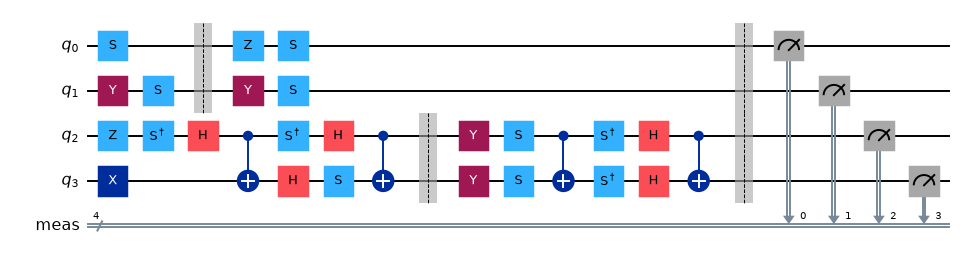

In [4]:
rng = np.random.default_rng(seed)
layer = ops.link_layers(4)[0]  # links 0-1 and 2-3
print("layer:", layer)

circuit = enc.build_layer_circuit(layer, 4, 1, rng)  # one random Clifford per link
display(circuit.draw("mpl", fold=40, scale=0.7))
plt.close()

*Figure: the circuit for the even layer with $m=1$. Qubits 0 and 1 hold the sequence for link 0-1, and qubits 2 and 3 hold the sequence for link 2-3. The last column measures all four qubits.*

Check that one pair's sequence is the identity. We build a sequence of 5 random Cliffords with its inverse and compare its unitary matrix with the identity.

In [5]:
sequence = ops.pair_sequence(5, rng)
print(
    "equals the identity (up to a global phase):",
    Operator(sequence).equiv(Operator(np.eye(4))),
)
print("gates in the circuit:", dict(sequence.count_ops()))

equals the identity (up to a global phase): True
gates in the circuit: {'h': 24, 'sdg': 13, 'cx': 12, 's': 11, 'x': 5, 'barrier': 5, 'y': 3, 'z': 1}


The circuit contains CX gates and one-qubit gates: `h`, `s`, `sdg`, `x`, `y`, `z`. The gate `x` flips 0 and 1, `y` flips them and adds a phase, and `z` flips the sign of the phase of 1. The gates `s` and `sdg` are quarter-turn phases: `s` multiplies the amplitude of 1 by $i$, and `sdg` multiplies it by $-i$, which undoes `s`.

Before running, `transpile_for` **transpiles** the circuit, which means it rewrites (compiles) every gate in the gates that the device supports. The **optimizer** is a compiler step that shortens a circuit by cancelling gates. We turn it **off**, because every sequence is the identity and an optimizer would delete it. We count the CX gates in the compiled circuits. In this model the CX gates carry all of the error, and on hardware they carry most of it, because two-qubit gates are about ten times worse than one-qubit gates. A random two-qubit Clifford needs about 1.5 CX gates on average, so we expect a count near 1.5.

## Step 3: Execution

There are 2 layers, 9 lengths, and 20 sequences per length, so $2 \times 9 \times 20 = 360$ circuits. They go out as **one job**, since on hardware the queue wait is paid per job.

On the simulator each CX has a depolarizing error that depends on its link, and read-out has an error. The decay rate of each link then follows from the numbers. The **signal** is the part of the answer that has not been scrambled. A depolarizing error $e$ on a CX multiplies the signal by $(1-e)$, because with probability $e$ the state is replaced by a random one. A Clifford with $k$ CX gates multiplies it by $(1-e)^k$. The built-in decay rate is the average of $(1-e)^k$ over random Cliffords:

$$p = \operatorname{mean}\,(1-e)^k.$$

Worked line: if every Clifford had the average $k = 1.5$ CX gates, link 0-1 ($e=0.010$) would have $p = 0.99^{1.5} = 0.985$. The real $k$ varies from Clifford to Clifford, so the exact mean differs slightly. The next cell runs the job and then computes the mean over a sample of random Cliffords.

In [6]:
data = execution.run(n_qubits, lengths, sequences, shots, backend_name, chain, seed)

print(f"{data['seconds']:.1f} s")
print(f"CX gates per two-qubit Clifford: {data['cx_per_clifford']:.2f}")
print("layers:", data["layers"])

if backend_name is None:
    truth = ops.simulator_truth(n_qubits)
    print(
        f"built-in p, link 0-1: {truth['0-1']['p']:.4f}   (0.99^1.5 = {0.99**1.5:.4f})"
    )

6.5 s
CX gates per two-qubit Clifford: 1.50
layers: [[[0, 1], [2, 3]], [[1, 2]]]


built-in p, link 0-1: 0.9847   (0.99^1.5 = 0.9850)


## Step 4: Analysis

### Fit every link

For each link we average the survival probability over the sequences of each length and fit $A\,p^m + B$, as in the randomized benchmarking notebook. The first figure shows one panel per link. Gray dots are single sequences and colored dots are their means. Each panel is titled with the link and its fitted decay rate $p$. The horizontal axis is the sequence length $m$ and the vertical axis is the survival probability. The curves that fall faster belong to the links with the larger error.

link             decay rate p       process fidelity  built in
0-1           0.9850 +/- 0.0013      0.9860 +/- 0.0012    0.9857
1-2           0.9662 +/- 0.0019      0.9683 +/- 0.0018    0.9644
2-3           0.9790 +/- 0.0016      0.9803 +/- 0.0015    0.9786

layer fidelity LF = 0.9359 +/- 0.0025   (built in: 0.9302)
EPLG              = 0.0175 +/- 0.0007   (built in: 0.0191)


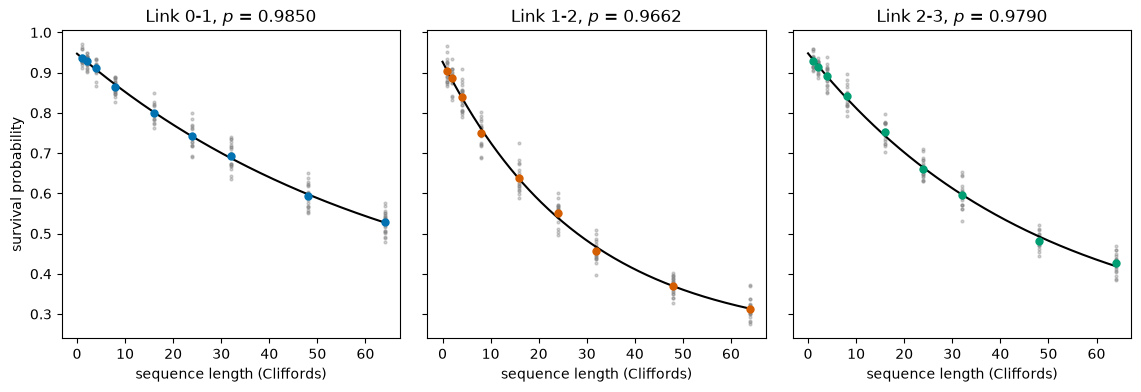

In [7]:
result = analysis.fit_layer(data)
analysis.print_table(data, result)

fig = analysis.plot_links(data, result)
display(fig)
plt.close(fig)

The table gives, for each link, the decay rate $p$ and the process fidelity, with their standard errors. On the simulator it also shows the value built into the noise model. The layer fidelity and the error per layered gate come below it. The error of the product comes from the errors of the links, which are independent. For independent errors, the relative errors add in quadrature: square each relative error (error divided by value), add the squares, and take the square root.

### Process fidelity of each link and the layer fidelity

The left panel shows the process fidelity of each link. The right panel shows the layer fidelity of the first $k$ links, which is how the fidelity falls as the chain grows.

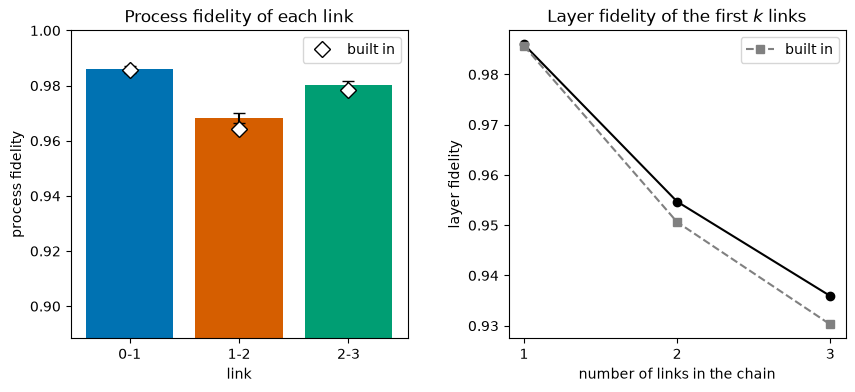

LF   = 0.9359 +/- 0.0025
EPLG = 0.0175 +/- 0.0007


In [8]:
fig = analysis.plot_layer(data, result)
display(fig)
plt.close(fig)

print(f"LF   = {result['lf']:.4f} +/- {result['lf_error']:.4f}")
print(f"EPLG = {result['eplg']:.4f} +/- {result['eplg_error']:.4f}")

**Stop and think.** Link 1-2 has the largest error, and the layer fidelity of the first two links drops the most. What would the layer fidelity of the chain be if we replaced link 1-2 with a link as good as 0-1? Use the process fidelities from the table.

In [9]:
pfs = {name: link["pf"] for name, link in result["links"].items()}
best = max(pfs.values())
improved = ops.layer_fidelity(
    [best if name == "1-2" else pf for name, pf in pfs.items()]
)
print(f"LF now: {result['lf']:.4f}")
print(f"LF with link 1-2 as good as the best link: {improved:.4f}")

LF now: 0.9359
LF with link 1-2 as good as the best link: 0.9530


**Answer.** The layer fidelity would rise to the second value printed above, a gain of about two percentage points. Link 1-2 is the weakest link, so replacing it gives the largest gain of any single link.

## Reading the results

- **The fit recovers the built-in fidelities.** Each link's process fidelity lies within a few standard errors of its built-in value, and so does the layer fidelity. Reruns with another `seed` move the numbers by about their error bars.
- **The weakest link costs the most.** Link 1-2 has a CX error 2.5 times that of link 0-1. Its built-in process error is 0.0356 against 0.0143 for link 0-1, a ratio of about 2.5. The ratio follows the CX error ratio because the process error is nearly proportional to the CX error. The left panel shows the weak link, and the single product does not, which is why both are reported.
- **EPLG lets chains of different lengths be compared.** A chain of 20 qubits has a smaller layer fidelity than one of 4 even if every link is the same. EPLG is that common link error.
- **Simplifications.** The definition used by IBM also runs one-qubit RB on the idle qubits (qubits that take no part in a gate of the layer) and handles the links between two gates of a layer in a more careful way. The notebook uses the principle (benchmark all links of a layer together, multiply) and leaves out these details.

On hardware, expect a smaller fidelity than the one on the calibration page (the device's published list of measured gate errors) for the same link, because the layer measurement includes crosstalk. Expect also that the weakest link is not the same on every day. Gate errors drift, and the first thing to look at when a layer fidelity falls is which link moved.

## What to try next

1. Change `SIM_LINK_ERROR` in `ops.py` to `(0.01, 0.01, 0.01)`. All links are alike now. Predict the layer fidelity and run it.
2. Set `n_qubits = 6` and rerun. The layer fidelity gets smaller because there are more factors in the product. Does EPLG change much? Explain why, using its definition as an average over links.
3. Call `execution.run(n_qubits, lengths, sequences, shots, backend_name, chain, seed, simultaneous=False)`, so each link runs alone (`simultaneous` is an argument of `execution.run`). Do the fidelities change on the simulator? What would you expect on hardware, and why?
4. Change `lengths` to `(1, 2, 4, 8)`. What happens to the error of $p$, and to the fidelity?
5. Increase `sequences` to 50. How much does the error of the layer fidelity shrink?
6. Replace the error of the middle link with `0.005` and `0.05`. How much does the layer fidelity depend on a single link?
7. Run on `ibm_rensselaer` with `chain = [0, 1, 2, 3]` (check the coupling map first), then with another chain. Which chain has the better layer fidelity?

## Terms

| Term | Plain definition | First used |
|---|---|---|
| layer fidelity (LF) | Score between 0 and 1 for a whole chain: the product of the process fidelities of its links | Intro |
| link | A pair of neighboring qubits that a two-qubit gate can act on | Intro |
| layer | A set of two-qubit gates, with no shared qubit, that run at the same time | Intro |
| crosstalk | A gate disturbing the qubits next to it | Intro |
| process fidelity (PF) | Score of one link that compares its whole input-to-output map with the ideal one: $\mathrm{PF} = p + (1-p)/d^2$ | Step 1 |
| Aer simulator | A program that applies gates and noise to the state by calculation | Setup |
| depolarizing error | With some probability the state is replaced by a random one | Setup |
| read-out error | Chance that a 0 is read as 1, or a 1 as 0 | Setup |
| sequence | $m$ random Cliffords followed by the Clifford that undoes them all | Setup |
| survival probability $F(m)$ | Fraction of shots in which both qubits read 0 | Step 1 |
| floor $B$ | Value of $F$ for a scrambled pair, $1/d = 1/4$ | Step 1 |
| average error $r$ | Chance of a wrong answer for a typical input: $r=(1-p)(d-1)/d$ | Step 1 |
| error per layered gate (EPLG) | Average error $r$ of a typical link of the chain | Step 1 |
| geometric mean | The $n$th root of a product of $n$ numbers | Step 1 |
| transpile | Rewrite a circuit in the gates a device supports | Step 2 |
| optimizer | A compiler step that shortens a circuit by cancelling gates | Step 2 |
| signal | The part of the answer that has not been scrambled | Step 3 |
| quadrature | For independent errors: square, add, take the square root | Step 4 |
| idle qubits | Qubits that take no part in a gate of the layer | Reading the results |
| calibration page | The device's published list of measured gate errors | Reading the results |